# Laboratorio 3: Generación de Datos Sintéticos y Modelado de Ruido Observacional

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nabw/UNA-taller/blob/main/notebooks/solucion/03_datos_sinteticos_ruido.ipynb)


## 1. Introducción: El Laboratorio in Silico

En la práctica de la ciencia de datos aplicada a sistemas dinámicos, rara vez se dispone de trayectorias continuas exactas y libres de error. Los registros clínicos y epidemiológicos se recolectan a intervalos discretos de tiempo (por ejemplo, reportes hospitalarios diarios) y están afectados por diversas fuentes de incertidumbre: errores de muestreo, subnotificación, sensibilidad imperfecta de las pruebas diagnósticas y demoras en el procesamiento de datos.

Para desarrollar y validar algoritmos de calibración e inferencia de parámetros (problemas inversos), es necesario contar con un entorno de prueba controlado: un **laboratorio in silico**. En este laboratorio generamos observaciones sintéticas a partir de un modelo mecanístico cuya **verdad de campo** (*Ground Truth*) conocemos con precisión absoluta. Esto permite cuantificar de forma rigurosa la exactitud, robustez y sesgo de los métodos de estimación.

## Objetivos de Aprendizaje

1. Simular la verdad de campo continua del modelo SIR ($\beta = 0.4$, $\gamma = 0.1$) mediante RK45 adaptativo.
2. Implementar el submuestreo temporal discreto en días enteros $t_k \in \{0, 1, 2, \dots, 50\}$.
3. Modelar el proceso observacional incorporando ruido Gaussiano $\mathcal{N}(0, \sigma^2)$ con proyección a no-negatividad física: $I^{\text{obs}} = \max(0, I + \varepsilon)$.
4. Efectuar un análisis estadístico riguroso de los residuos observacionales (media, desviación estándar, banda $\pm 2\sigma$).
5. Visualizar las observaciones clínicas y caracterizar la incertidumbre instrumental.


In [1]:
# Celda de configuración y librerías científicas
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
from typing import Any
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "figure.titlesize": 13,
    "lines.linewidth": 2.0,
    "grid.alpha": 0.4
})

print("Configuración inicial completada.")


Configuración inicial completada.


## 2. Generación de la Verdad de Campo (Ground Truth)

Consideramos el sistema continuo SIR:

$$\frac{dS}{dt} = -\beta S I$$
$$\frac{dI}{dt} = \beta S I - \gamma I$$
$$\frac{dR}{dt} = \gamma I$$

con parámetros nominales verdaderos:
- $\beta^* = 0.40$ (tasa de transmisión)
- $\gamma^* = 0.10$ (tasa de recuperación)
- $R_0^* = \beta^* / \gamma^* = 4.00$
- Condiciones iniciales: $S(0) = 0.99$, $I(0) = 0.01$, $R(0) = 0.00$
- Horizonte temporal: $T = 50.0$ días

Generamos la trayectoria continua evaluada en una malla densa con RK45 adaptativo.


In [2]:
def generar_verdad_campo(
    beta: float = 0.4,
    gamma: float = 0.1,
    S0: float = 0.99,
    I0: float = 0.01,
    T: float = 50.0,
    dt_eval: float = 0.005
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Genera la solución continua de referencia (Ground Truth) para el modelo SIR.
    """
    R0_val = 1.0 - S0 - I0
    y0 = np.array([S0, I0, R0_val], dtype=np.float64)

    def sir_ode(t: float, y: np.ndarray) -> np.ndarray:
        s, i, r = y
        ds = -beta * s * i
        di = beta * s * i - gamma * i
        dr = gamma * i
        return np.array([ds, di, dr], dtype=np.float64)

    n_points = int(np.round(T / dt_eval)) + 1
    t_eval = np.linspace(0.0, T, n_points)

    sol = solve_ivp(
        sir_ode,
        t_span=(0.0, T),
        y0=y0,
        t_eval=t_eval,
        method="RK45",
        rtol=1e-10,
        atol=1e-12
    )
    return sol.t, sol.y[0], sol.y[1], sol.y[2]


In [3]:
# Pruebas de validación para generar_verdad_campo
t_ref, S_ref, I_ref, R_ref = generar_verdad_campo(0.4, 0.1, 0.99, 0.01, 50.0)
assert np.isclose(S_ref[0], 0.99) and np.isclose(I_ref[0], 0.01), "Condiciones iniciales incorrectas."
assert np.max(np.abs(S_ref + I_ref + R_ref - 1.0)) < 1e-6, "Conservación de masa no satisfecha."
print("Validación de generar_verdad_campo: EXITOSA.")


Validación de generar_verdad_campo: EXITOSA.


## 3. Muestreo en Tiempos de Reporte Clínico Discreto

En los sistemas de vigilancia epidemiológica, las notificaciones se registran en días enteros: $t_k \in \{0, 1, 2, \dots, 50\}$. Interpolar la trayectoria continua de referencia sobre estos puntos discretos produce la serie temporal libre de ruido, denominada $I^{\text{clean}}(t_k)$.


In [4]:
def muestrear_dias_enteros(
    t_ref: np.ndarray,
    I_ref: np.ndarray,
    t_dias: np.ndarray = None
) -> tuple[np.ndarray, np.ndarray]:
    """
    Submuestrea la serie continua de infectados sobre instantes de tiempo discretos.
    """
    if t_dias is None:
        T_final = float(t_ref[-1])
        t_dias = np.arange(0.0, T_final + 1.0, 1.0)
    else:
        t_dias = np.asarray(t_dias, dtype=np.float64)

    I_clean = np.interp(t_dias, t_ref, I_ref)
    return t_dias, I_clean


In [5]:
# Pruebas de validación para muestrear_dias_enteros
t_dias, I_clean = muestrear_dias_enteros(t_ref, I_ref)
assert len(t_dias) == 51, f"Se esperaban 51 puntos diarios (0 a 50), obtenidos {len(t_dias)}"
assert np.isclose(t_dias[0], 0.0) and np.isclose(t_dias[-1], 50.0), "Los extremos temporales no coinciden."
assert np.all(I_clean >= 0.0) and np.all(I_clean <= 1.0), "Valores fuera del rango físico [0, 1]."
print("Validación de muestrear_dias_enteros: EXITOSA.")


Validación de muestrear_dias_enteros: EXITOSA.


## 4. Proceso de Medición: Ruido Gaussiano y Proyección Física

Para modelar el error observacional aditivo, perturbamos las mediciones con variables aleatorias normales independientes e idénticamente distribuidas:

$$\varepsilon_k \sim \mathcal{N}(0, \sigma^2), \quad \sigma = 0.02$$

Dado que $I(t)$ representa la proporción de la población infectada, una observación negativa es físicamente inadmisible. Imponemos la proyección no lineal sobre el conjunto de estados válidos mediante la operación de truncamiento inferior:

$$I^{\text{obs}}_k = \max(0, I^{\text{clean}}(t_k) + \varepsilon_k)$$

Para garantizar reproducibilidad científica estricta, fijamos la semilla del generador pseudoaleatorio.


In [6]:
def agregar_ruido_gaussiano(
    I_clean: np.ndarray,
    sigma: float = 0.02,
    seed: int = 42
) -> np.ndarray:
    """
    Agrega ruido aditivo Gaussiano N(0, sigma^2) con proyección a no-negatividad.
    """
    I_arr = np.asarray(I_clean, dtype=np.float64)
    rng = np.random.default_rng(seed)
    noise = rng.normal(loc=0.0, scale=sigma, size=I_arr.shape)
    I_noisy = np.maximum(0.0, I_arr + noise)
    return I_noisy


In [7]:
# Pruebas de validación para agregar_ruido_gaussiano
I_obs_test = agregar_ruido_gaussiano(I_clean, sigma=0.02, seed=42)
assert I_obs_test.shape == I_clean.shape, "La forma del arreglo no coincide."
assert np.all(I_obs_test >= 0.0), "Violación de no-negatividad física."
# Verificar determinismo mediante semilla fija
I_obs_test2 = agregar_ruido_gaussiano(I_clean, sigma=0.02, seed=42)
assert np.array_equal(I_obs_test, I_obs_test2), "El generador debe ser determinista con semilla fija."
print("Validación de agregar_ruido_gaussiano: EXITOSA.")


Validación de agregar_ruido_gaussiano: EXITOSA.


## 5. Análisis Estadístico de Residuos Observacionales

Definimos el residuo observacional en cada instante muestral como la desviación entre el valor observado y el valor real subyacente:

$$e_k = I^{\text{obs}}_k - I^{\text{clean}}(t_k)$$

Propiedades estadísticas a verificar:
1. **Media muestral**: $\bar{e} = \frac{1}{M} \sum_{k=1}^M e_k \approx 0$, lo que confirma la ausencia de sesgo sistemático en el proceso de captura.
2. **Desviación estándar muestral**: $s_e = \sqrt{\frac{1}{M-1} \sum_{k=1}^M (e_k - \bar{e})^2} \approx \sigma = 0.02$.
3. **Banda de confianza $\pm 2\sigma$**: Para una distribución Gaussiana, aproximadamente el $95.4\%$ de las observaciones deben residir dentro del intervalo $[-\text{2}\sigma, +\text{2}\sigma]$.


In [8]:
def analizar_residuos(
    I_clean: np.ndarray,
    I_obs: np.ndarray,
    sigma: float = 0.02
) -> dict[str, Any]:
    """
    Calcula los estadísticos descriptivos de los residuos observacionales.
    """
    residuos = np.asarray(I_obs, dtype=np.float64) - np.asarray(I_clean, dtype=np.float64)
    media = float(np.mean(residuos))
    std = float(np.std(residuos, ddof=1))
    dentro_banda = np.abs(residuos) <= 2.0 * sigma
    pct_banda = float(np.mean(dentro_banda)) * 100.0

    return {
        "residuos": residuos,
        "media": media,
        "desviacion_std": std,
        "porcentaje_2sigma": pct_banda
    }


In [9]:
# Pruebas de validación para analizar_residuos
stats = analizar_residuos(I_clean, I_obs_test, sigma=0.02)
assert isinstance(stats, dict), "La función debe retornar un diccionario."
assert "media" in stats and "desviacion_std" in stats and "porcentaje_2sigma" in stats
assert abs(stats["media"]) < 0.01, f"Media residual excesiva: {stats['media']}"
assert 0.01 < stats["desviacion_std"] < 0.03, f"Desviación residual anormal: {stats['desviacion_std']}"
print("Validación de analizar_residuos: EXITOSA.")


Validación de analizar_residuos: EXITOSA.


## 6. Generación Completa y Caracterización Gráfica

Ejecutamos el flujo completo de generación con la semilla $42$ y $\sigma = 0.02$. Construimos dos gráficos científicos:
1. **Curva de referencia continua frente a las observaciones discretas**, incluyendo la banda de dispersión $\pm 2\sigma$.
2. **Serie temporal de los residuos**, contrastada contra las bandas de control $\pm 2\sigma$.


In [10]:
sigma = 0.02
seed = 42

t_dias, I_clean = muestrear_dias_enteros(t_ref, I_ref)
I_obs = agregar_ruido_gaussiano(I_clean, sigma=sigma, seed=seed)
analisis = analizar_residuos(I_clean, I_obs, sigma=sigma)

print("=" * 65)
print("ANÁLISIS ESTADÍSTICO DE RESIDUOS OBSERVACIONALES")
print("=" * 65)
print(f"Número de observaciones discretas: {len(t_dias)}")
print(f"Desviación estándar nominal (sigma): {sigma:.4f}")
print(f"Media muestral de residuos:        {analisis['media']:+.5f}")
print(f"Desviación estándar muestral (s):  {analisis['desviacion_std']:.5f}")
print(f"Observaciones en banda +- 2*sigma: {analisis['porcentaje_2sigma']:.1f}% (esperado: ~95.4%)")
print("=" * 65)

ANÁLISIS ESTADÍSTICO DE RESIDUOS OBSERVACIONALES
Número de observaciones discretas: 51
Desviación estándar nominal (sigma): 0.0200
Media muestral de residuos:        +0.00218
Desviación estándar muestral (s):  0.01468
Observaciones en banda +- 2*sigma: 98.0% (esperado: ~95.4%)


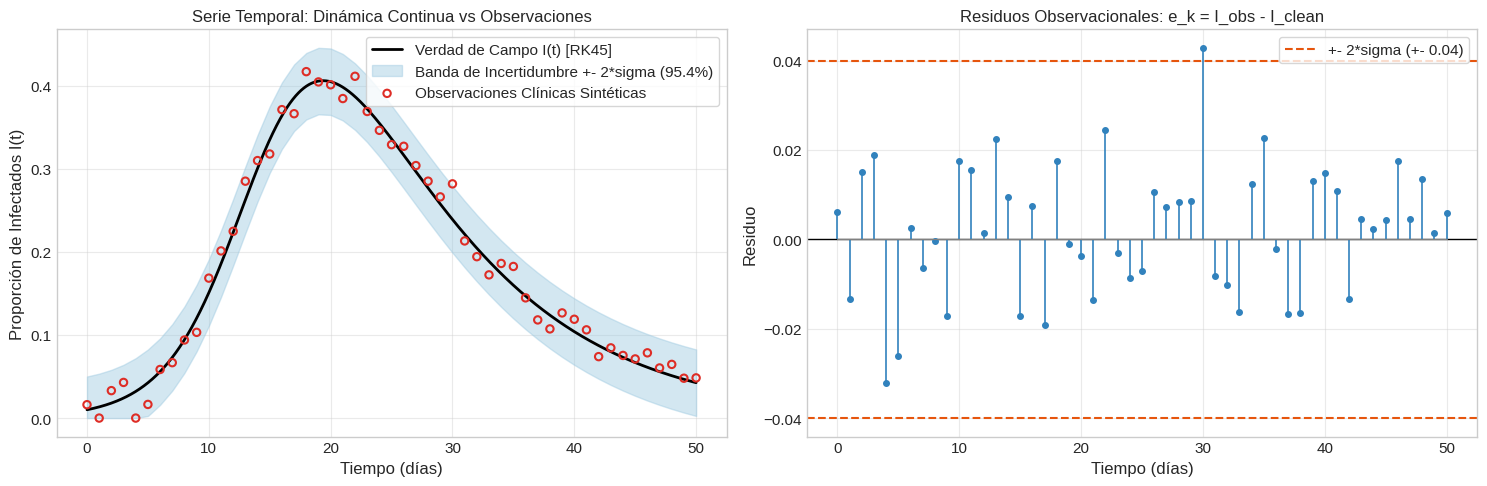

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel 1: Curva de verdad de campo y observaciones ruidosas
ax1 = axes[0]
ax1.plot(t_ref, I_ref, 'k-', linewidth=2.0, label="Verdad de Campo I(t) [RK45]", zorder=2)
ax1.fill_between(
    t_dias,
    np.maximum(0.0, I_clean - 2 * sigma),
    I_clean + 2 * sigma,
    color="#9ecae1",
    alpha=0.45,
    label="Banda de Incertidumbre +- 2*sigma (95.4%)",
    zorder=1
)
ax1.scatter(
    t_dias, I_obs, color="#de2d26", s=28, facecolors="none", edgecolors="#de2d26",
    linewidths=1.5, label="Observaciones Clínicas Sintéticas", zorder=3
)
ax1.set_title("Serie Temporal: Dinámica Continua vs Observaciones")
ax1.set_xlabel("Tiempo (días)")
ax1.set_ylabel("Proporción de Infectados I(t)")
ax1.legend(frameon=True, loc="upper right")

# Panel 2: Serie temporal de residuos con bandas de control
ax2 = axes[1]
residuos = analisis["residuos"]
ax2.axhline(0.0, color="black", linestyle="-", linewidth=1.0)
ax2.axhline(+2 * sigma, color="#e6550d", linestyle="--", linewidth=1.5, label="+- 2*sigma (+- 0.04)")
ax2.axhline(-2 * sigma, color="#e6550d", linestyle="--", linewidth=1.5)
markerline, stemlines, baseline = ax2.stem(t_dias, residuos, linefmt="b-", markerfmt="bo", basefmt="k-")
plt.setp(stemlines, linewidth=1.2, color="#3182bd")
plt.setp(markerline, markersize=4, color="#3182bd")
plt.setp(baseline, linewidth=0.8, color="gray")
ax2.set_title("Residuos Observacionales: e_k = I_obs - I_clean")
ax2.set_xlabel("Tiempo (días)")
ax2.set_ylabel("Residuo")
ax2.legend(frameon=True, loc="upper right")

plt.tight_layout()
plt.show()


## 7. Lectura Complementaria: Datos Discretos de Conteo

En este laboratorio hemos modelado el error mediante ruido Gaussiano continuo y homocedástico. Sin embargo, en entornos hospitalarios donde se registran conteos enteros de personas (por ejemplo, admisiones diarias), la variabilidad del proceso de notificación es intrínsecamente discreta y heterocedástica: la varianza de los datos depende directamente de la magnitud media esperada de los casos.

Para los estudiantes interesados en profundizar en el modelado estadístico de conteo mediante procesos Poissonianos y verosimilitud de Poisson, se recomienda consultar el documento conceptual de apoyo:

[Lectura Complementaria: Modelado de Ruido de Conteo y Distribución de Poisson](../../appendix/ruido_conteo_poisson.md)
